### Business Problem
Swiggy processes millions of food-delivery journeys across hundreds of cities every month. Accurate Estimated Time of Arrival (ETA) at order placement and during delivery is core to the customer experience — it affects conversion, cancellations, ratings, and retention. Today’s ETA accuracy suffers from many sources of uncertainty: highly variable traffic patterns, weather events, restaurant preparation variability, rider behaviour and skill, order batching/multiple deliveries, and city-specific operational constraints. Inaccurate ETAs cause:
Reduced customer trust and lower repeat orders.
* Increased cancellations and refund costs.
* Higher support volume and operational interventions.
* Sub-optimal rider allocation and increased rider idle or overtime costs.


### Data Understanding

In [26]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error,mean_absolute_error,r2_score
from sklearn.model_selection import KFold,cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
import pickle

In [27]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\swiggy_demographic.csv")

In [28]:
df.head()

,rider_id,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_date,weather,traffic,...,time_taken,city_name,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,sunny,high,...,24,INDO,19,3,saturday,1,15.0,11.0,morning,3.025149
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,stormy,jam,...,33,BANG,25,3,friday,0,5.0,19.0,evening,20.183530
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,sandstorms,low,...,26,BANG,19,3,saturday,1,15.0,8.0,morning,1.552758
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,sunny,medium,...,21,COIMB,5,4,tuesday,0,10.0,18.0,evening,7.790401
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,cloudy,high,...,30,CHEN,26,3,saturday,1,15.0,13.0,afternoon,6.210138


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45502 entries, 0 to 45501
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   rider_id              45502 non-null  object 
 1   age                   43648 non-null  float64
 2   ratings               43594 non-null  float64
 3   restaurant_latitude   41872 non-null  float64
 4   restaurant_longitude  41872 non-null  float64
 5   delivery_latitude     41872 non-null  float64
 6   delivery_longitude    41872 non-null  float64
 7   order_date            45502 non-null  object 
 8   weather               44977 non-null  object 
 9   traffic               44992 non-null  object 
 10  vehicle_condition     45502 non-null  int64  
 11  type_of_order         45502 non-null  object 
 12  type_of_vehicle       45502 non-null  object 
 13  multiple_deliveries   44509 non-null  float64
 14  festival              45274 non-null  object 
 15  city_type          

In [31]:
df.columns

Index(['rider_id', 'age', 'ratings', 'restaurant_latitude',
       'restaurant_longitude', 'delivery_latitude', 'delivery_longitude',
       'order_date', 'weather', 'traffic', 'vehicle_condition',
       'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival',
       'city_type', 'time_taken', 'city_name', 'order_day', 'order_month',
       'order_day_of_week', 'is_weekend', 'pickup_time_minutes',
       'order_time_hour', 'order_time_of_day', 'distance'],
      dtype='object')

In [32]:
df.duplicated().sum()

np.int64(0)

In [33]:
df.isna().sum()

rider_id                   0
age                     1854
ratings                 1908
restaurant_latitude     3630
restaurant_longitude    3630
delivery_latitude       3630
delivery_longitude      3630
order_date                 0
weather                  525
traffic                  510
vehicle_condition          0
type_of_order              0
type_of_vehicle            0
multiple_deliveries      993
festival                 228
city_type               1198
time_taken                 0
city_name                  0
order_day                  0
order_month                0
order_day_of_week          0
is_weekend                 0
pickup_time_minutes     1640
order_time_hour         1640
order_time_of_day          0
distance                3630
dtype: int64

### Data Preprocessing

In [34]:
target_variable = ['time_taken']
numerical_cols = ['age','ratings','vehicle_condition','multiple_deliveries','is_weekend','pickup_time_minutes','distance','order_day','order_month','order_time_hour']
categorical_cols = ['weather','traffic','type_of_order','type_of_vehicle','festival','city_type','city_name','order_day_of_week','order_time_of_day']

### EDA

In [35]:
# univariate analysis

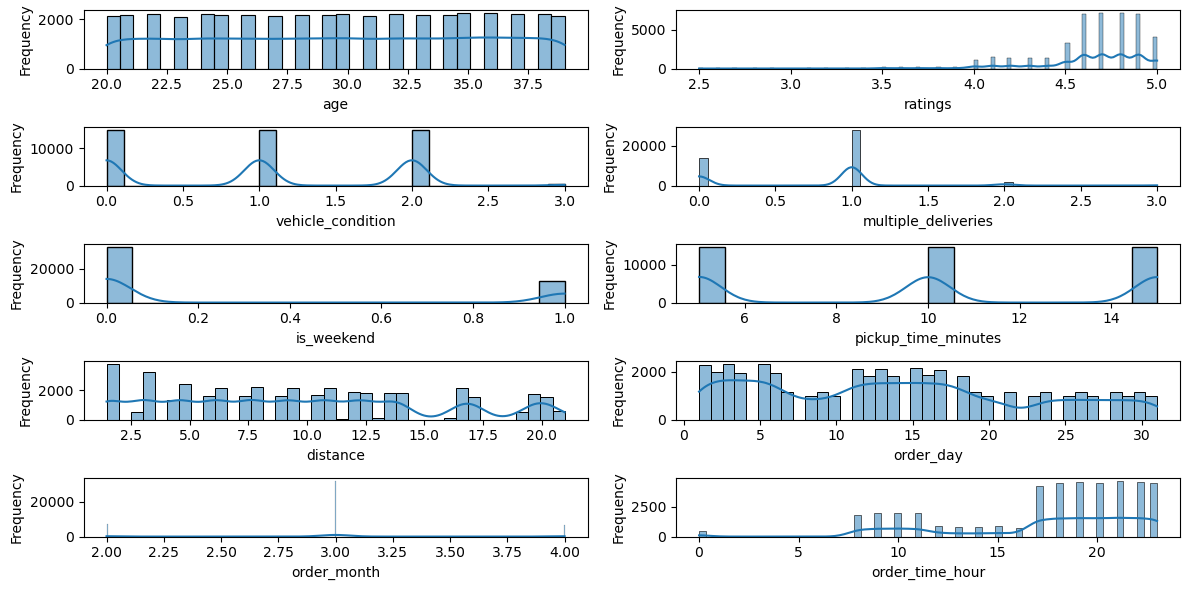

In [36]:
# numerical columns distribution
plt.figure(figsize=(12,6))
for i ,col in enumerate(numerical_cols,1):
    plt.subplot(5,2,i)
    sns.histplot(df[col],kde=True)
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

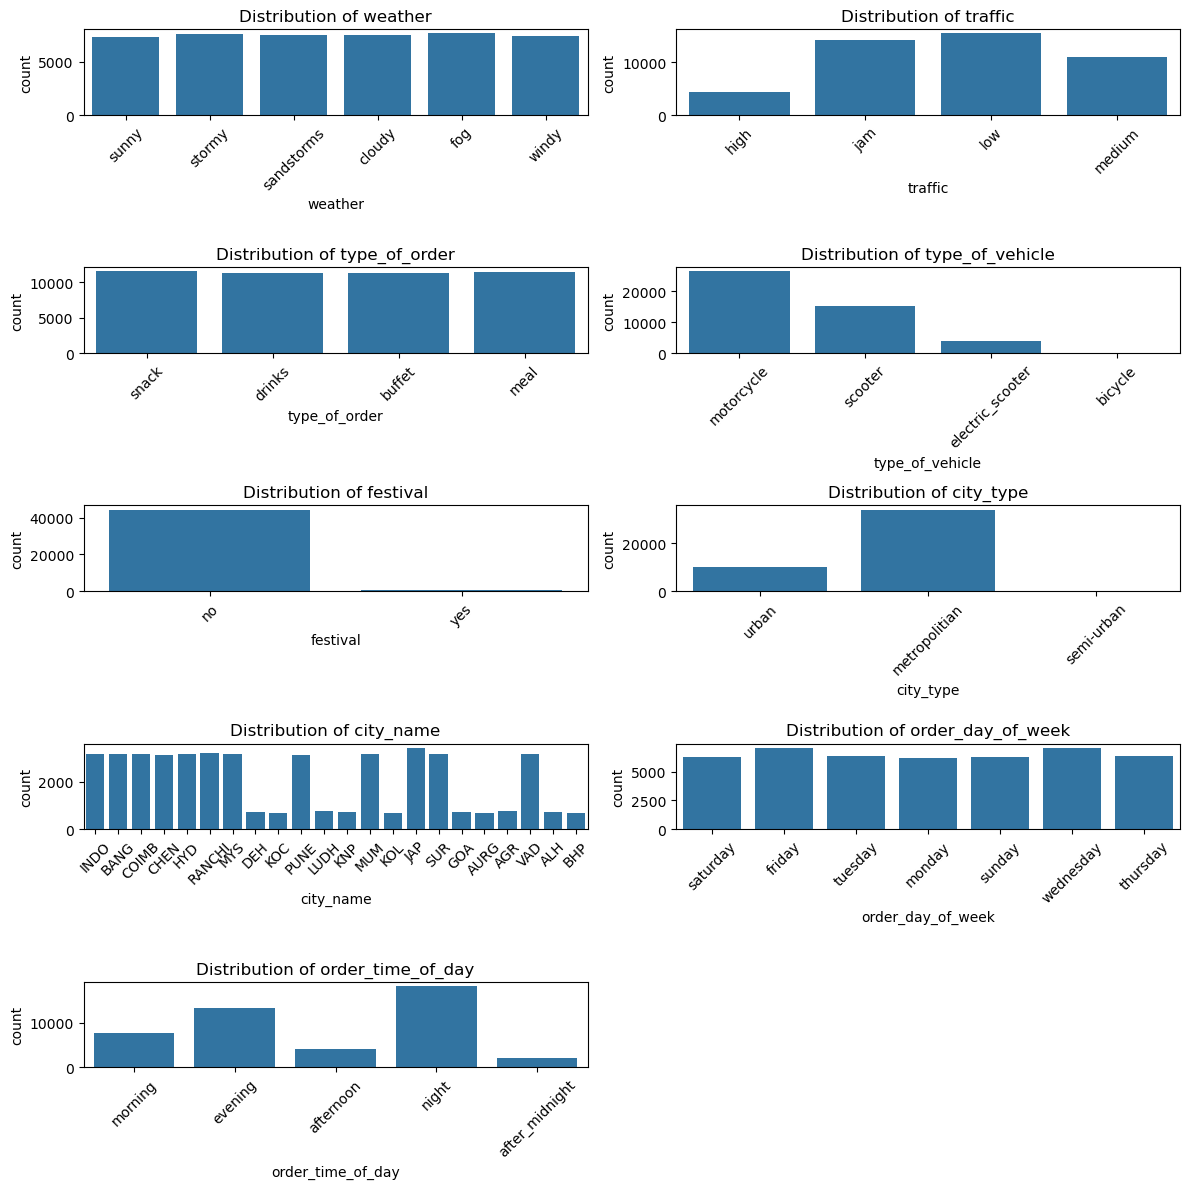

In [37]:
# categorical columns frequency
plt.figure(figsize=(12,12))
for i,col in enumerate(categorical_cols,1):
    plt.subplot(5,2,i)
    sns.countplot(data=df, x=col)
    plt.title('Distribution of ' + col)
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

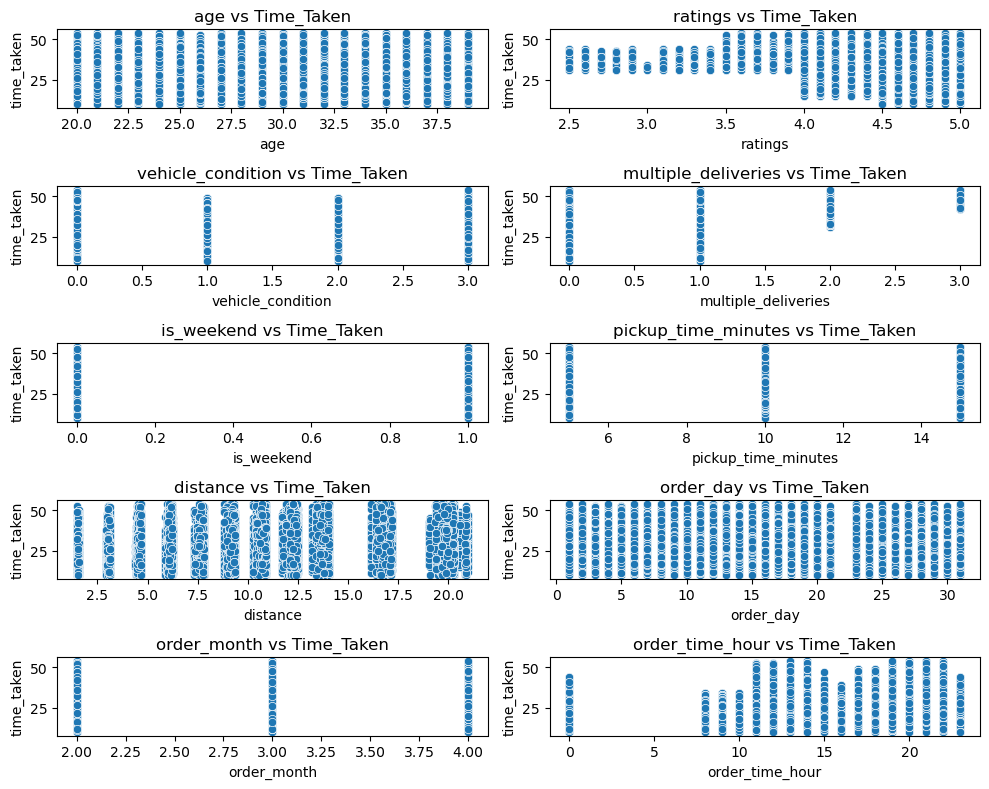

In [38]:
# Relationship of numerical columns with time-taken
plt.figure(figsize=(10,8))
for i,col in enumerate(numerical_cols,1):
    plt.subplot(5,2,i)
    sns.scatterplot(x=df[col], y=df['time_taken'])
    plt.title(f'{col} vs Time_Taken')
    plt.xlabel(col)
    plt.ylabel('time_taken')
plt.tight_layout()
plt.show()

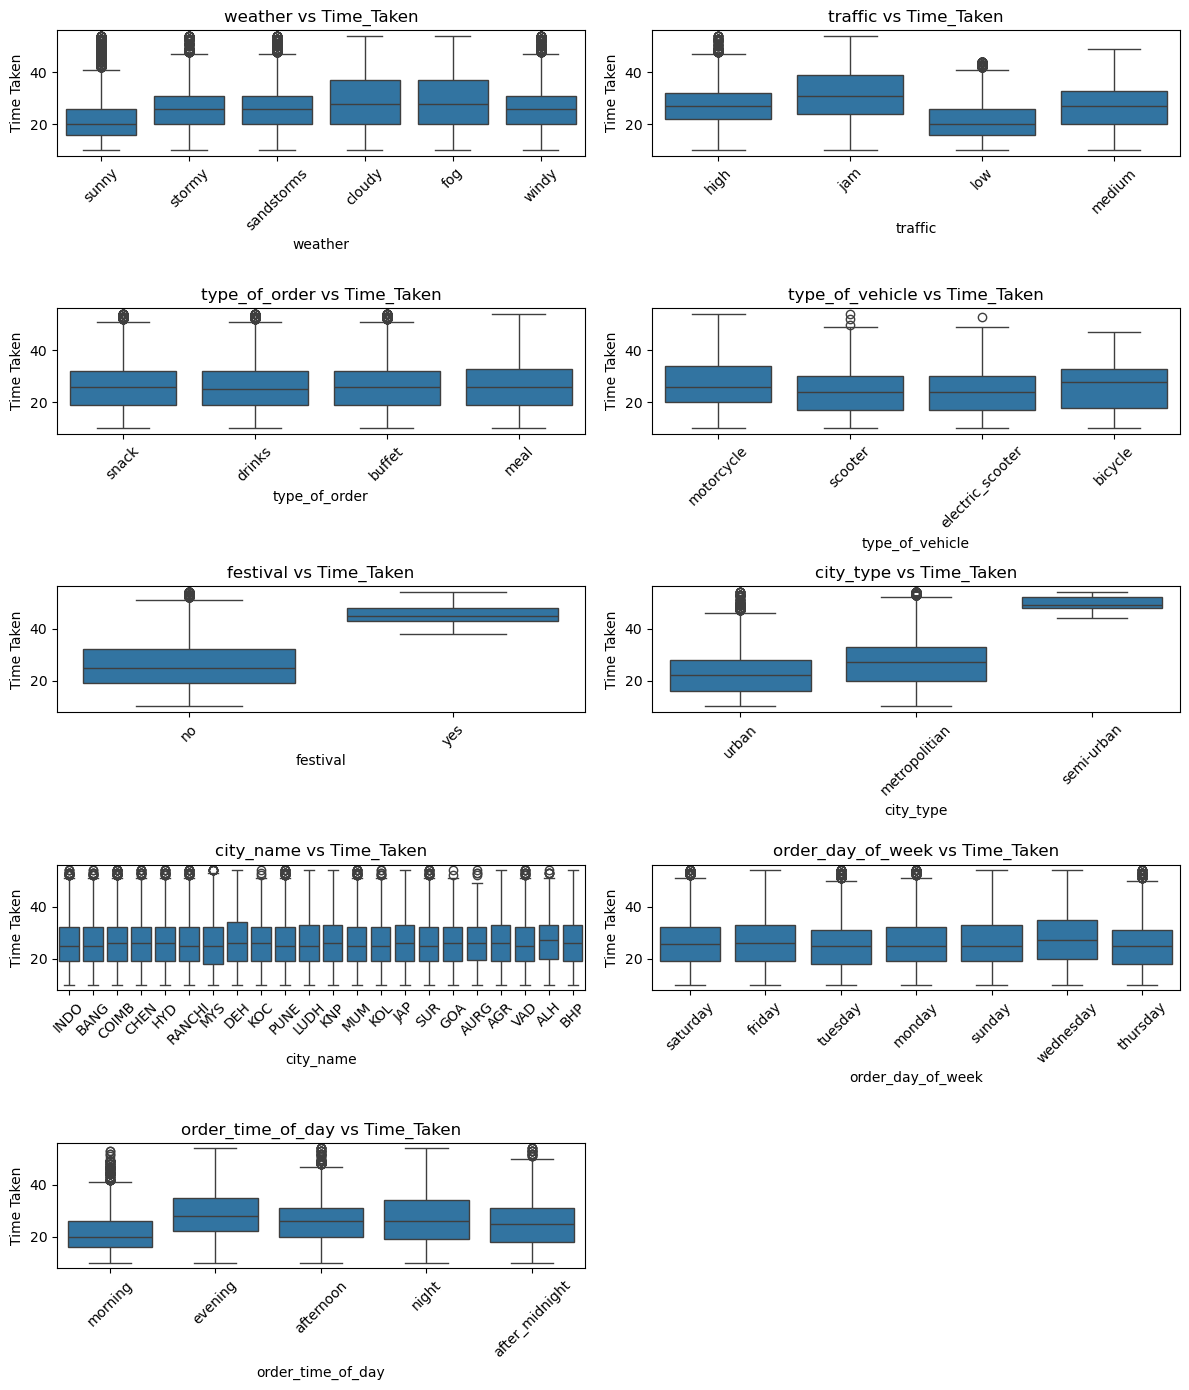

In [39]:
# Relationship of categorical columns with time taken
plt.figure(figsize=(12,14))
for i, col in enumerate(categorical_cols,1):
    plt.subplot(5,2,i)
    sns.boxplot(x=df[col], y=df['time_taken'])
    plt.title(f'{col} vs Time_Taken')
    plt.xlabel(col)
    plt.ylabel('Time Taken')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

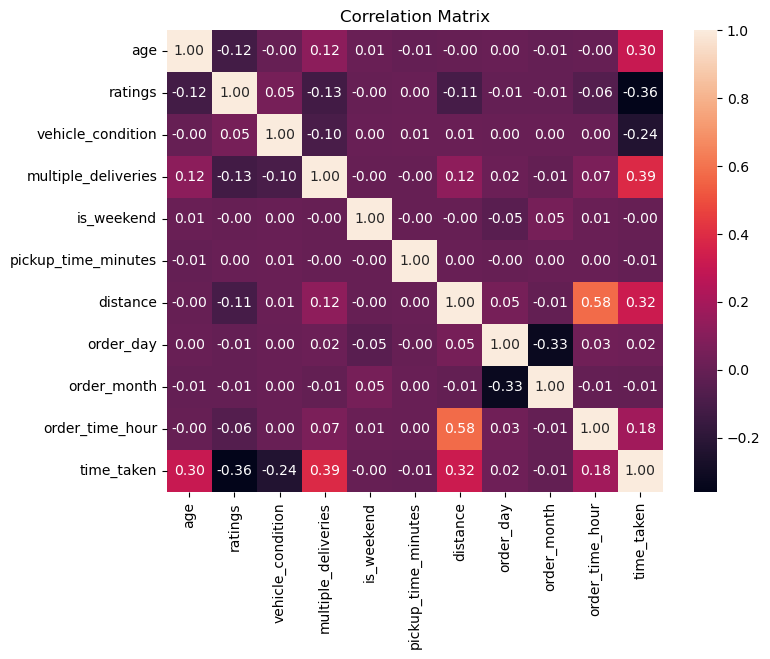

In [40]:
# correlation of all numerical cols
corr_cols = numerical_cols + target_variable
corr_matrix = df[corr_cols].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [41]:
# skewness
for col in numerical_cols + target_variable:
    print(col,'=',df[col].skew())

age = -0.014541859592086096
ratings = -1.7931177887882865
vehicle_condition = 0.06068312407407523
multiple_deliveries = 0.32500404219094625
is_weekend = 1.0085867102342039
pickup_time_minutes = 0.003900099686574291
distance = 0.32501795920821824
order_day = 0.29909432132155994
order_month = -0.012455528534165806
order_time_hour = -1.0235680889508263
time_taken = 0.485582469348261


In [42]:
# splitting data into input and output 
X = df[numerical_cols+categorical_cols]
y = df['time_taken']

In [43]:
# splitting into train and test
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=23)

### With Pipeline

In [111]:
numerical_transformer = Pipeline([('Imputation',SimpleImputer(strategy='median')),
                                 ('Transformer',PowerTransformer()),
                                 ('Scaling',StandardScaler())])

In [112]:
numerical_transformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Imputation', ...), ('Transformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimator

In [113]:
nominal_cols = ['weather','type_of_order','type_of_vehicle','festival','city_name','order_day_of_week']
ordinal_cols = ['traffic','city_type','order_time_of_day']

In [114]:
nominal_transformer = Pipeline([('Mode Imputation',SimpleImputer(strategy='most_frequent')),
                               ('One Hot Encoding',OneHotEncoder())])

In [115]:
nominal_transformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Mode Imputation', ...), ('One Hot Encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predicti

In [116]:
df['traffic'].unique()

array(['high', 'jam', 'low', 'medium', nan], dtype=object)

In [117]:
df['city_type'].unique()

array(['urban', 'metropolitian', 'semi-urban', nan], dtype=object)

In [118]:
df['order_time_of_day'].unique()

array(['morning', 'evening', 'afternoon', 'night', 'after_midnight'],
      dtype=object)

In [119]:
cat_order = [['jam','high','medium','low'],['semi-urban','urban','metropolitian'],['morning','afternoon','evening','night','after_midnight']]

In [120]:
ordinal_transformer = Pipeline([('Mode Imputation',SimpleImputer(strategy='most_frequent')),
                               ('Ordinal Encoding',OrdinalEncoder(categories=cat_order))])

In [121]:
ordinal_transformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Mode Imputation', ...), ('Ordinal Encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predicti

In [122]:
preprocessing = ColumnTransformer([('Numerical Transformer',numerical_transformer,numerical_cols),
                                  ('Nominal Transformer',nominal_transformer,nominal_cols),
                                  ('Ordinal Transformer',ordinal_transformer,ordinal_cols)])

In [124]:
preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``

### Linear Regression

In [125]:
lr = Pipeline([('Data preprocessing',preprocessing),
              ('Model Building',LinearRegression())])
lr.fit(X_train,y_train)
y_test_pred = lr.predict(X_test)
y_train_pred = lr.predict(X_train)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  6.294799006252077
Testing RMSE :  6.23283382033859
Training MAE :  5.0088884428107106
Testing MAE :  4.977568458644089
Training r2 score :  0.5491806098664793
Testing r2 score :  0.5630627266546679


### KNN

In [126]:
knn = Pipeline([('Data preprocessing',preprocessing),
              ('Model Building',KNeighborsRegressor())])
knn.fit(X_train,y_train)
y_test_pred = knn.predict(X_test)
y_train_pred = knn.predict(X_train)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  4.790754742980474
Testing RMSE :  5.894142921403967
Training MAE :  3.7246833878190153
Testing MAE :  4.617558510053841
Training r2 score :  0.7388760368942446
Testing r2 score :  0.6092586944354617


### Random Forest

In [127]:
rf = Pipeline([('Data preprocessing',preprocessing),
              ('Model Building',RandomForestRegressor())])
rf.fit(X_train,y_train)
y_test_pred = rf.predict(X_test)
y_train_pred = rf.predict(X_train)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  1.5442795726060021
Testing RMSE :  4.1217073949089755
Training MAE :  1.2023573528199774
Testing MAE :  3.2416580595538953
Training r2 score :  0.9728674441620134
Testing r2 score :  0.8089256841419965


### Decision Tree

In [128]:
dt = Pipeline([('Data preprocessing',preprocessing),
              ('Model Building',DecisionTreeRegressor())])
dt.fit(X_train,y_train)
y_test_pred = dt.predict(X_test)
y_train_pred = dt.predict(X_train)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  0.0
Testing RMSE :  5.612451819559449
Training MAE :  0.0
Testing MAE :  4.239094604988463
Training r2 score :  1.0
Testing r2 score :  0.6457146045335895


### SVR

In [129]:
svr = Pipeline([('Data preprocessing',preprocessing),
              ('Model Building',SVR())])
svr.fit(X_train,y_train)
y_test_pred = svr.predict(X_test)
y_train_pred = svr.predict(X_train)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  5.126519330121237
Testing RMSE :  5.173358973027944
Training MAE :  3.96632819219526
Testing MAE :  4.084664972295782
Training r2 score :  0.7009911445915715
Testing r2 score :  0.6989814720438423


### xgboost

In [130]:
xgboost = Pipeline([('Data preprocessing',preprocessing),
              ('Model Building',XGBRegressor())])
xgboost.fit(X_train,y_train)
y_test_pred = xgboost.predict(X_test)
y_train_pred = xgboost.predict(X_train)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  3.469109296798706
Testing RMSE :  4.097390651702881
Training MAE :  2.754478693008423
Testing MAE :  3.2518954277038574
Training r2 score :  0.8630775213241577
Testing r2 score :  0.8111736178398132


### Cross validation

In [131]:
kf = KFold(n_splits=5,shuffle=True,random_state=23)
cross_val_score(xgboost,X_train,y_train,scoring='r2',cv=kf).mean()

np.float64(0.8055349469184876)

### Hyperparameter tuning

In [132]:
# grid search cv
search_space = {'Model Building__n_estimators': [100, 200, 300],'Model Building__max_depth': [4, 6, 7, 8],'Model Building__learning_rate': [0.05, 0.1, 0.01]}

grid_xgb = GridSearchCV(estimator=xgboost,param_grid=search_space,cv=kf,scoring='r2')

In [133]:
grid_xgb.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model Building__learning_rate': [0.05, 0.1, ...], 'Model Building__max_depth': [4, 6, ...], 'Model Building__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchang

In [134]:
grid_xgb.best_params_

{'Model Building__learning_rate': 0.05,
 'Model Building__max_depth': 8,
 'Model Building__n_estimators': 200}

In [135]:
grid_xgb.best_score_

np.float64(0.8150646567344666)

In [136]:
xgboost = Pipeline([('Data preprocessing',preprocessing),
              ('Model Building',XGBRegressor(learning_rate= 0.05,max_depth= 8,n_estimators= 100))])
xgboost.fit(X_train,y_train)
y_test_pred = xgboost.predict(X_test)
y_train_pred = xgboost.predict(X_train)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  3.7037572860717773
Testing RMSE :  3.989088535308838
Training MAE :  2.9401676654815674
Testing MAE :  3.1759743690490723
Training r2 score :  0.8439283967018127
Testing r2 score :  0.8210237622261047


At first i got overfitting issue then i changed parameters to get best r2 score

In [69]:
#with open(r'C:\swiggy\swiggy_model.pkl','wb') as file:
 #   pickle.dump(xgboost,file)

### Without Pipeline

In [70]:
target_variable = ['time_taken']
numerical_cols = ['age','ratings','vehicle_condition','multiple_deliveries','is_weekend','pickup_time_minutes','distance','order_day','order_month','order_time_hour']

nominal_cols = ['weather','type_of_order','type_of_vehicle','festival','city_name','order_day_of_week']
ordinal_cols = ['traffic','city_type','order_time_of_day']

In [71]:
# splitting data into input and output 
X = df[numerical_cols+categorical_cols]
y = df['time_taken']

In [72]:
# splitting into train and test
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=23)

In [73]:
df.isnull().sum()

rider_id                   0
age                     1854
ratings                 1908
restaurant_latitude     3630
restaurant_longitude    3630
delivery_latitude       3630
delivery_longitude      3630
order_date                 0
weather                  525
traffic                  510
vehicle_condition          0
type_of_order              0
type_of_vehicle            0
multiple_deliveries      993
festival                 228
city_type               1198
time_taken                 0
city_name                  0
order_day                  0
order_month                0
order_day_of_week          0
is_weekend                 0
pickup_time_minutes     1640
order_time_hour         1640
order_time_of_day          0
distance                3630
dtype: int64

In [74]:
# filling missing values

In [137]:
# for numerical cols
num_imputer = SimpleImputer(strategy='median')
X_train_num = num_imputer.fit_transform(X_train[numerical_cols])
X_test_num = num_imputer.transform(X_test[numerical_cols])

In [138]:
# for categorical cols
nominal_imputer = SimpleImputer(strategy='most_frequent')
X_train_nominal = nominal_imputer.fit_transform(X_train[nominal_cols])
X_test_nominal = nominal_imputer.transform(X_test[nominal_cols])

In [139]:
ord_imputer = SimpleImputer(strategy='most_frequent')
X_train_ord = ord_imputer.fit_transform(X_train[ordinal_cols])
X_test_ord = ord_imputer.transform(X_test[ordinal_cols])

### Encoding

In [140]:
# one-hot encoding
ohe_nominal = OneHotEncoder(handle_unknown='ignore',sparse_output=False)
X_train_ohe = pd.DataFrame(ohe_nominal.fit_transform(X_train_nominal),columns = ohe_nominal.get_feature_names_out(nominal_cols))
X_test_ohe = pd.DataFrame(ohe_nominal.transform(X_test_nominal),columns = ohe_nominal.get_feature_names_out(nominal_cols))

In [141]:
X_train_ohe

,weather_cloudy,weather_fog,weather_sandstorms,weather_stormy,weather_sunny,weather_windy,type_of_order_buffet,type_of_order_drinks,type_of_order_meal,type_of_order_snack,...,city_name_RANCHI,city_name_SUR,city_name_VAD,order_day_of_week_friday,order_day_of_week_monday,order_day_of_week_saturday,order_day_of_week_sunday,order_day_of_week_thursday,order_day_of_week_tuesday,order_day_of_week_wednesday
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36396,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
36397,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
36398,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
36399,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [142]:
X_test_ohe

,weather_cloudy,weather_fog,weather_sandstorms,weather_stormy,weather_sunny,weather_windy,type_of_order_buffet,type_of_order_drinks,type_of_order_meal,type_of_order_snack,...,city_name_RANCHI,city_name_SUR,city_name_VAD,order_day_of_week_friday,order_day_of_week_monday,order_day_of_week_saturday,order_day_of_week_sunday,order_day_of_week_thursday,order_day_of_week_tuesday,order_day_of_week_wednesday
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9096,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9097,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
9098,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9099,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [143]:
cat_order = [['jam','high','medium','low'],['semi-urban','urban','metropolitian'],['morning','afternoon','evening','night','after_midnight']]
oe = OrdinalEncoder(categories=cat_order)
X_train_oe = pd.DataFrame(oe.fit_transform(X_train_ord),columns = oe.get_feature_names_out(ordinal_cols))
X_test_oe = pd.DataFrame(oe.transform(X_test_ord),columns = oe.get_feature_names_out(ordinal_cols))

In [144]:
X_train_oe

,traffic,city_type,order_time_of_day
0,2.0,2.0,2.0
1,3.0,2.0,3.0
2,0.0,2.0,2.0
3,3.0,2.0,3.0
4,3.0,2.0,3.0
...,...,...,...
36396,2.0,2.0,2.0
36397,1.0,2.0,0.0
36398,0.0,2.0,3.0
36399,0.0,2.0,3.0


In [145]:
X_test_oe

,traffic,city_type,order_time_of_day
0,3.0,2.0,3.0
1,3.0,2.0,3.0
2,2.0,1.0,2.0
3,0.0,2.0,3.0
4,3.0,1.0,0.0
...,...,...,...
9096,2.0,2.0,2.0
9097,2.0,2.0,2.0
9098,0.0,2.0,3.0
9099,3.0,2.0,0.0


In [146]:
scaling = StandardScaler()
X_train_num_scaling = pd.DataFrame(scaling.fit_transform(X_train_num),columns = scaling.get_feature_names_out(numerical_cols))
X_test_num_scaling = pd.DataFrame(scaling.transform(X_test_num),columns = scaling.get_feature_names_out(numerical_cols))

In [147]:
X_train_num_scaling

,age,ratings,vehicle_condition,multiple_deliveries,is_weekend,pickup_time_minutes,distance,order_day,order_month,order_time_hour
0,0.078216,-0.451007,1.172118,0.443797,1.617588,1.247399,-0.353085,-0.090357,0.031089,0.110592
1,-0.631352,1.175576,-0.024860,0.443797,-0.618204,0.001916,-0.964384,0.139199,-1.797151,1.165368
2,-1.695704,0.199626,-1.221837,0.443797,1.617588,-1.243567,0.224936,1.516531,0.031089,0.321547
3,0.255608,-2.402907,1.172118,0.443797,-0.618204,-1.243567,1.957670,0.483532,0.031089,0.954413
4,-0.099176,0.850260,-1.221837,0.443797,-0.618204,1.247399,0.465756,0.024421,0.031089,0.954413
...,...,...,...,...,...,...,...,...,...,...
36396,0.787784,-1.752274,-1.221837,0.443797,-0.618204,-1.243567,-0.086692,0.483532,-1.797151,-0.100363
36397,-0.808744,-0.125690,-0.024860,-1.320968,1.617588,-1.243567,-1.231650,-1.008578,0.031089,-1.366095
36398,-1.163528,-0.125690,-0.024860,0.443797,-0.618204,1.247399,0.224451,0.253976,0.031089,0.743458
36399,-1.340920,0.850260,-1.221837,-1.320968,-0.618204,1.247399,-0.966587,0.139199,-1.797151,0.532503


In [148]:
X_test_num_scaling

,age,ratings,vehicle_condition,multiple_deliveries,is_weekend,pickup_time_minutes,distance,order_day,order_month,order_time_hour
0,0.433000,1.175576,1.172118,0.443797,1.617588,1.247399,-0.063843,1.401753,0.031089,1.165368
1,-0.631352,0.199626,-0.024860,-1.320968,1.617588,1.247399,-0.393139,1.401753,0.031089,1.165368
2,1.142568,0.199626,-0.024860,0.443797,-0.618204,1.247399,-0.086692,0.368754,0.031089,-0.100363
3,1.319960,0.850260,-1.221837,0.443797,1.617588,-1.243567,0.194639,1.516531,0.031089,0.743458
4,-0.631352,0.850260,1.172118,-1.320968,-0.618204,-1.243567,-1.508626,-1.467688,0.031089,-1.998961
...,...,...,...,...,...,...,...,...,...,...
9096,1.142568,-3.053541,-0.024860,-1.320968,-0.618204,-1.243567,0.168643,1.746086,0.031089,-0.100363
9097,-0.099176,0.850260,1.172118,0.443797,-0.618204,1.247399,0.198428,1.057420,0.031089,0.321547
9098,-1.518312,0.199626,-1.221837,2.208562,-0.618204,1.247399,1.201163,0.024421,-1.797151,0.743458
9099,1.674744,-0.125690,-0.024860,0.443797,1.617588,-1.243567,-1.512654,-1.008578,0.031089,-1.577050


In [149]:
# combining all into dataframe
X_train_final = pd.concat([X_train_num_scaling,X_train_ohe,X_train_oe],axis=1)
X_test_final = pd.concat([X_test_num_scaling,X_test_ohe,X_test_oe],axis=1)

In [150]:
X_train_final.shape

(36401, 58)

In [151]:
X_train_final.shape

(36401, 58)

In [152]:
X_train_final.isna().sum()

age                                 0
ratings                             0
vehicle_condition                   0
multiple_deliveries                 0
is_weekend                          0
pickup_time_minutes                 0
distance                            0
order_day                           0
order_month                         0
order_time_hour                     0
weather_cloudy                      0
weather_fog                         0
weather_sandstorms                  0
weather_stormy                      0
weather_sunny                       0
weather_windy                       0
type_of_order_buffet                0
type_of_order_drinks                0
type_of_order_meal                  0
type_of_order_snack                 0
type_of_vehicle_bicycle             0
type_of_vehicle_electric_scooter    0
type_of_vehicle_motorcycle          0
type_of_vehicle_scooter             0
festival_no                         0
festival_yes                        0
city_name_AG

In [153]:
X_test_final.isna().sum()

age                                 0
ratings                             0
vehicle_condition                   0
multiple_deliveries                 0
is_weekend                          0
pickup_time_minutes                 0
distance                            0
order_day                           0
order_month                         0
order_time_hour                     0
weather_cloudy                      0
weather_fog                         0
weather_sandstorms                  0
weather_stormy                      0
weather_sunny                       0
weather_windy                       0
type_of_order_buffet                0
type_of_order_drinks                0
type_of_order_meal                  0
type_of_order_snack                 0
type_of_vehicle_bicycle             0
type_of_vehicle_electric_scooter    0
type_of_vehicle_motorcycle          0
type_of_vehicle_scooter             0
festival_no                         0
festival_yes                        0
city_name_AG

### Linear Regression

In [154]:
lr = LinearRegression()
lr.fit(X_train_final,y_train)
y_test_pred = lr.predict(X_test_final)
y_train_pred = lr.predict(X_train_final)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  6.1620657729404265
Testing RMSE :  6.112554369542907
Training MAE :  4.9092371321068935
Testing MAE :  4.8881044696088525
Training r2 score :  0.5679922765845367
Testing r2 score :  0.5797637923856921


### KNN

In [93]:
knn = KNeighborsRegressor()
knn.fit(X_train_final,y_train)
y_test_pred = knn.predict(X_test_final)
y_train_pred = knn.predict(X_train_final)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  4.760165007843562
Testing RMSE :  5.832509325908458
Training MAE :  3.70074448504162
Testing MAE :  4.55569717613449
Training r2 score :  0.7422000273235057
Testing r2 score :  0.6173877398254076


### Random Forest

In [94]:
rf = RandomForestRegressor()
rf.fit(X_train_final,y_train)
y_test_pred = rf.predict(X_test_final)
y_train_pred = rf.predict(X_train_final)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  1.5302377928072632
Testing RMSE :  4.072469816395199
Training MAE :  1.1922743880662618
Testing MAE :  3.210279090209867
Training r2 score :  0.973358621092282
Testing r2 score :  0.8134635331040904


### Decision Tree

In [95]:
dt = DecisionTreeRegressor()
dt.fit(X_train_final,y_train)
y_test_pred = dt.predict(X_test_final)
y_train_pred = dt.predict(X_train_final)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  0.0
Testing RMSE :  5.552627022391899
Training MAE :  0.0
Testing MAE :  4.204263267772772
Training r2 score :  1.0
Testing r2 score :  0.653227217706


### SVR 

In [96]:
svr = SVR()
svr.fit(X_train_final,y_train)
y_test_pred = svr.predict(X_test_final)
y_train_pred = svr.predict(X_train_final)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  5.08791343187074
Testing RMSE :  5.135111062590346
Training MAE :  3.934678473696983
Testing MAE :  4.054759316156924
Training r2 score :  0.7054776352484557
Testing r2 score :  0.7034160258118816


### xgboost

In [97]:
xgboost = XGBRegressor()
xgboost.fit(X_train_final,y_train)
y_test_pred = xgboost.predict(X_test_final)
y_train_pred = xgboost.predict(X_train_final)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  3.4583137035369873
Testing RMSE :  4.079953193664551
Training MAE :  2.7418110370635986
Testing MAE :  3.2286558151245117
Training r2 score :  0.8639283776283264
Testing r2 score :  0.8127774000167847


### cross validation

In [98]:
kf = KFold(n_splits=5,shuffle=True,random_state=23)
cross_val_score(xgboost,X_train_final,y_train,scoring='r2',cv=kf).mean()

np.float64(0.8060986757278442)

### Hyperparameter tuning

In [99]:
# grid search cv
search_space = {'n_estimators': [100, 200, 300],'max_depth': [4, 6, 7, 8],'learning_rate': [0.05, 0.1, 0.01]}
grid_xgb = GridSearchCV(estimator=xgboost,param_grid=search_space,cv=kf,scoring='r2')

In [100]:
grid_xgb.fit(X_train_final,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1, ...], 'max_depth': [4, 6, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"ve

In [101]:
grid_xgb.best_params_

{'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 100}

In [102]:
grid_xgb.best_score_

np.float64(0.8182166457176209)

In [103]:
xgboost = XGBRegressor(learning_rate= 0.05, max_depth= 8, n_estimators= 100)
xgboost.fit(X_train_final,y_train)
y_test_pred = xgboost.predict(X_test_final)
y_train_pred = xgboost.predict(X_train_final)
print('Training RMSE : ',root_mean_squared_error(y_train,y_train_pred))
print('Testing RMSE : ',root_mean_squared_error(y_test,y_test_pred))
print('Training MAE : ',mean_absolute_error(y_train,y_train_pred))
print('Testing MAE : ',mean_absolute_error(y_test,y_test_pred))
print('Training r2 score : ',r2_score(y_train,y_train_pred))
print('Testing r2 score : ',r2_score(y_test,y_test_pred))

Training RMSE :  3.688262939453125
Testing RMSE :  3.9450323581695557
Training MAE :  2.925244092941284
Testing MAE :  3.1434109210968018
Training r2 score :  0.8452314734458923
Testing r2 score :  0.8249552249908447


In [ ]:
# age,gender,rating(1,5),study(school-graduation)
num_cols = ['age','rating']
nominal_cols = ['gender']
ordinal_cols = ['study']

numerical_transformer = Pipeline(['numerical_transformer',num_cols])
nominal_transformer = Pipeline(['nominal_transformer',nominal_cols])
ordinal_transformer = Pipeline('ordinal_transformer',ordinal_cols)

col_t = ColumnTransformer([numerical_transformer,nominal_transformer,ordinal_transformer],SVR())

svr = SVR()
svr.fit(X_train,y_train)
y_train_pred = svr.predict(X_train)
y_test_pred = svr.predict(X_test)
print(root_mean_squared_error(y_test,y_pred))
print(r2_score(y_test,y_test_pred))
print(r2_score(y_train,y_train_pred))
